## ReAct Architecture
-> Act
-> Observe
-> Reason

In [18]:
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

searchTool = TavilySearch(max_results=1)
# Custom function
@tool
def multiple(a:int, b:int) -> int:
    """
    Multiple a and b
    Args:
        a (int): first number
        b (int): second number
    Returns:
        int: output int
    """
    return a * b

tools = [searchTool, multiple]
# llm
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b")
# bind tools to llm
llm_with_tools = llm.bind_tools(tools)

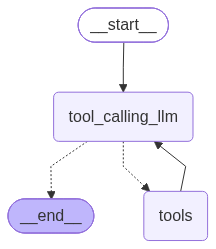

In [19]:
# StateGraph
from typing import Annotated
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# State
class State(TypedDict):
    messages: Annotated[list,add_messages]

# Node definitions
def tool_calling_llm(state:State):
    response = llm_with_tools.invoke(state["messages"])
    return { "messages" : [response]}

# Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # if the latest message is a tool call, then go to the tool node
    # if the latest message is not a tool call, then go to the END node
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

# Compile
graph = builder.compile()

# Visualize
display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
response = graph.invoke({
    "messages" : ["What is the recent tweet from @elonmusk? about ambani and then multiple of 5 and 6"]
})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent tweet from @elonmusk? about ambani and then multiple of 5 and 6
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_068abddd-ffc4-4053-8014-9f7b03eb36d9)
 Call ID: fc_068abddd-ffc4-4053-8014-9f7b03eb36d9
  Args:
    query: Elon Musk tweet Ambani
    search_depth: fast
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "Elon Musk tweet Ambani", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.tmz.com/2026/10/09/elon-musk-kicked-daughter-off-insurance-after-she-came-out-as-trans/", "title": "Elon Musk Kicked Daughter Off Insurance After She Came Out as Trans, First Wife Says - TMZ", "score": 1.0, "published_date": "Sat, 10 Oct 2026 00:54:50 GMT", "content": "# Elon Musk Kicked Daughter Off I

## Adding memory to Agentic Graph

In [22]:
response = graph.invoke({ "messages" : ["Hi,How are you doing?"]})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi,How are you doing?
================================== Ai Message ==================================

Hello! I’m doing great, thank you for asking. How can I assist you today?


In [23]:
response = graph.invoke({ "messages" : ["What is my name?"]})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

I’m afraid I don’t have any information about your name. If you’d like me to address you a certain way, just let me know!


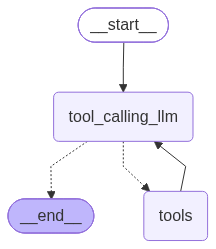

In [24]:
# StateGraph
from typing import Annotated
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver
# ⬆️ newly added
memory = MemorySaver()

# State
class State(TypedDict):
    messages: Annotated[list,add_messages]

# Node definitions
def tool_calling_llm(state:State):
    response = llm_with_tools.invoke(state["messages"])
    return { "messages" : [response]}

# Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # if the latest message is a tool call, then go to the tool node
    # if the latest message is not a tool call, then go to the END node
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

# Compile
graph = builder.compile(checkpointer=memory)

# Visualize
display(Image(graph.get_graph().draw_mermaid_png()))

In [28]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}


response = graph.invoke({"messages" : ["My name is Koduru Nirmal Nethra"]},config=config)
print(response["messages"][-1].content)

Got it—nice to meet you, **Koduru Nirmal Nethra**! If there's anything specific you'd like help with, just let me know.


In [29]:
response = graph.invoke({"messages" : ["Hey! what is my name?"]},config=config)
print(response["messages"][-1].content)

Your name is **Koduru Nirmal Nethra**.


## Steaming

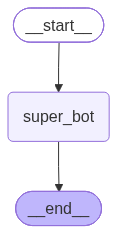

In [39]:
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph,START,END
from IPython.display import Image, display
memory_loader = MemorySaver()

def super_bot(state:State):
    response = llm_with_tools.invoke(state["messages"])
    return { "messages" : [response]}

builder = StateGraph(State)
# add node
builder.add_node("super_bot",super_bot)

# add edges
builder.add_edge(START,"super_bot")
builder.add_edge("super_bot",END)

graph = builder.compile(checkpointer=memory_loader)

# visualize
display(Image(graph.get_graph().draw_mermaid_png()))


In [40]:
# streaming
config = {
    "configurable": {
        "thread_id": "3"
    }
}
for chunk in graph.stream({"messages" : ["Hi"]},config=config,stream_mode="updates"):
    print(chunk)

{'super_bot': {'messages': [AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi". We should respond politely. No need to use tools.'}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 366, 'total_tokens': 403, 'completion_time': 0.077774736, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.014880083, 'prompt_tokens_details': None, 'queue_time': 0.385430684, 'total_time': 0.092654819}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8655ddce88', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12524-68e7-7933-92e7-38748453c899-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 366, 'output_tokens': 37, 'total_tokens': 403, 'output_token_details': {'reasoning': 19}})]}}


In [41]:
for chunk in graph.stream({"messages" : ["How are you?"]},config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='ecfbc6bf-d4a6-4772-a5ce-c72b6a2c6218'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi". We should respond politely. No need to use tools.'}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 366, 'total_tokens': 403, 'completion_time': 0.077774736, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.014880083, 'prompt_tokens_details': None, 'queue_time': 0.385430684, 'total_time': 0.092654819}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8655ddce88', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12524-68e7-7933-92e7-38748453c899-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 366, 'output_tokens': 37, 'total_tokens': 403, 'output_token_details': {'reasoning': 19}}), Huma

In [36]:
config = {
    "configurable": {
        "thread_id": "4"
    }
}
for chunk in graph.stream({"messages" : ["Hi,My name is John i like cricket"]},config=config,stream_mode="updates"):
    print(chunk)

{'super_bot': {'messages': [AIMessage(content='Hi John! 👋 Great to meet you.  \n\nCricket’s a fantastic sport—do you have a favorite team or player? And is there anything specific you’d like to chat about or need help with today?', additional_kwargs={'reasoning_content': 'User says hi, introduces themselves. We should respond friendly, ask about cricket, maybe ask how can help.'}, response_metadata={'token_usage': {'completion_tokens': 76, 'prompt_tokens': 374, 'total_tokens': 450, 'completion_time': 0.156901546, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.016326494, 'prompt_tokens_details': None, 'queue_time': 0.210633925, 'total_time': 0.17322804}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4727af4560', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12522-3277-7d72-96d0-de52f976abb6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 374, 'output_to

In [42]:
for chunk in graph.stream({"messages" : ["I also like playing football"]},config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='ecfbc6bf-d4a6-4772-a5ce-c72b6a2c6218'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi". We should respond politely. No need to use tools.'}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 366, 'total_tokens': 403, 'completion_time': 0.077774736, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.014880083, 'prompt_tokens_details': None, 'queue_time': 0.385430684, 'total_time': 0.092654819}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8655ddce88', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12524-68e7-7933-92e7-38748453c899-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 366, 'output_tokens': 37, 'total_tokens': 403, 'output_token_details': {'reasoning': 19}}), Huma